# Prototipe beban kognitif lima tingkat: pengukuran HRV dan mata

Keluaran pada tampilan adalah **Low / Mid low / Mid / Mid high / High**. Target ini bukan tingkat kesulitan tugas.

Notebook ini melatih tiga keluarga model pada setiap dataset, lalu menjelaskan skor dan grafik hasilnya. Setiap model mempunyai **cabang HRV** dan **cabang mata**. Skornya digabungkan dengan bobot **60% HRV / 40% mata** sebelum tingkat beban ditentukan. Perbandingan sensitivitas terhadap pembobotan 50/50 juga tersedia.

Hasil ini merupakan **estimasi relatif sementara berbasis sensor**. Kita terlebih dahulu menetapkan acuan dari pengukuran sensor, lalu melatih model untuk mendekatinya. Kesesuaian model menunjukkan keberhasilan meniru definisi tersebut; hasilnya belum menjadi akurasi pengukuran beban kognitif yang divalidasi secara independen.

Secara bawaan, notebook memakai mode tinjauan untuk membuka hasil selesai yang sesuai dengan data masukan dan konfigurasi. Ubah `TRAIN_NEW_RUN = True` jika ingin melatih model baru. Nama kolom data, nilai label asli, dan antarmuka Python tetap dipertahankan untuk menjaga kompatibilitas model.


## 1. Persiapan

Pilih kernel Python di VS Code atau Jupyter. Jika diperlukan, pasang dependensi melalui terminal dari direktori utama repositori:

```powershell
python -m pip install -r analysis_sessions/model_training/requirements-notebook.txt
```

Jalankan sel secara berurutan dari atas ke bawah. Pelatihan dengan pencarian `compact` dapat memerlukan beberapa menit karena setiap peserta uji membutuhkan acuan tersendiri, validasi internal, dan dua cabang model.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import sys

# Dapat dijalankan dari direktori utama repositori atau direktori notebook.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'analysis_sessions/model_training/train_models.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Buka notebook ini dari dalam repositori AdaptiveIDE.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import joblib
from IPython.display import display, Markdown, Image
from analysis_sessions.model_training import data, reference, train_models as training, visualize as visual
from analysis_sessions.model_training.predict import predict_windows
from analysis_sessions.model_training.presentation import display_frame, LEVEL_NAMES, NOTE_ID
print('Repositori:', ROOT)
print('Tingkat keluaran:', ' / '.join(LEVEL_NAMES[level] for level in data.LEVELS))


Repositori: D:\CODINGGG\AdaptiveIDE
Tingkat keluaran: Low / Mid low / Mid / Mid high / High


## 2. Pilih data ekspor, bobot, dan pengaturan pelatihan

Setiap direktori ekspor memuat `good_only.csv`, `good_acceptable.csv`, `all_data.csv`, dan `feature_columns.json`. Tambahkan hasil temanmu dengan ukuran jendela lain sebagai entri terpisah. Setiap kelompok memiliki acuan serta perbandingannya sendiri; tingkat dari ukuran jendela berbeda tidak otomatis setara secara universal.

Konfigurasi bawaan memakai 24 kandidat prediktor: **3 fitur HRV dan 21 fitur mata/konteks**. Proporsi status mata belum terklasifikasi atau lainnya hanya menjadi diagnostik kualitas. Tingkat kesulitan tugas dan identitas peserta atau soal tidak masuk sebagai prediktor model.

Asumsi eksperimen dapat diubah dalam `config.json`. Perubahan konfigurasi membutuhkan pelatihan baru agar hasilnya sesuai. Bobot ini merupakan pilihan untuk prototipe, bukan konstanta fisiologis yang sudah ditetapkan.


In [2]:
DATASETS = [
    ('window25_step5', ROOT / 'analysis_sessions/dataset_fusion/output'),
    # Tambahkan hasil ekspor lain sebagai pasangan ID dan direktori.
    # ('window40_step5', ROOT / 'path/to/friends/export'),
]
SELECTED_DATASET = 'window25_step5'
CONFIG = data.load_config()
SEARCH = 'compact'       # 'quick' memakai satu pengaturan per keluarga model
TRAIN_NEW_RUN = False    # True: latih dan simpan sembilan paket dua cabang per kelompok
RUN_DIRECTORY = None    # None: direktori baru atau hasil selesai terbaru yang sesuai
FAMILY_DIAGNOSTICS = True

loaded = {name: data.load_dataset(path, CONFIG) for name, path in DATASETS}
if SELECTED_DATASET not in loaded:
    raise ValueError('SELECTED_DATASET harus sesuai dengan salah satu ID pada DATASETS.')
print('Bobot utama:', CONFIG['primary_hrv_weight'], 'HRV /', 1-CONFIG['primary_hrv_weight'], 'mata')
for name, dataset in loaded.items():
    display(Markdown(f'### {name}: jendela {dataset["window_seconds"]:g} detik'))
    display(display_frame(pd.DataFrame([{'Training dataset': variant, 'Total windows': len(frame),
                                        'Scorable windows': int(data.eligible(frame).sum()),
                                        'Unscorable windows': int((~data.eligible(frame)).sum()),
                                        'Participants': frame.participant_id.nunique()}
                                       for variant, frame in dataset['views'].items()])))


Bobot utama: 0.6 HRV / 0.4 mata


### window25_step5: jendela 25 detik

,Training dataset,Total windows,Scorable windows,Unscorable windows,Participants
0,Good only,639,639,0,5
1,Good + acceptable,2294,2101,193,13
2,All data,3546,3126,420,18


## 3. Arti skor sementara

**Acuan HRV:** bandingkan rasio RMSSD terhadap acuan istirahat dengan rekaman latih berkualitas baik. Rasio yang lebih rendah memperoleh skor acuan HRV yang lebih tinggi.

**Acuan mata:** bandingkan frekuensi kedipan dan proporsi estimasi fiksasi dengan rekaman latih berkualitas baik. Frekuensi kedipan lebih rendah dan proporsi fiksasi lebih tinggi memperoleh skor komponen yang lebih tinggi. Kedua komponen mata berbobot sama. Ini merupakan asumsi eksperimen; kode tidak menyatakan bahwa setiap kenaikan EAR, ukuran iris, atau posisi tatapan berarti beban meningkat.

**Model mata** dapat memakai kedipan, EAR, geometri iris, statistik tatapan, pola status mata, dan konteks kepala untuk memprediksi skor acuan mata. Memasukkan fitur tersebut tidak menjadikannya pengukuran beban independen. Estimasi ukuran iris bukan diameter pupil.

Skor gabungan dihitung sebagai `0.60 * skor HRV + 0.40 * skor mata`. Empat batas persentil dari acuan latih membentuk lima tingkat. Setiap peserta memperoleh total bobot acuan yang sama, dan nilai sensor yang identik tetap mendapat peringkat yang sama. Pengukuran acuan yang hilang menghasilkan status **sinyal tidak mencukupi**, bukan label Low yang dibuat-buat.

Selama evaluasi, setiap acuan hanya dibentuk dari peserta latih, termasuk pada validasi internal untuk memilih parameter. Semua varian data menggunakan acuan dan jendela uji yang sama dalam pembagian evaluasi yang sama. Setelah evaluasi, model akhir memakai acuan bersama dari seluruh jendela latih berkualitas baik.


## 4. Latih model atau tinjau hasil yang sesuai

Setiap pembagian evaluasi memisahkan satu peserta beserta seluruh rekamannya dari pelatihan. Setiap model memiliki regresor HRV dan mata yang terpisah: RBF-SVM untuk regresi (SVR), Random Forest, atau Gradient Boosting. Regresi menghasilkan skor kontinu sebelum skor dipetakan menjadi lima tingkat berurutan.

Pencarian `compact` memilih pengaturan cabang berdasarkan rata-rata galat skor per peserta. Prapemrosesan dan acuan dibentuk ulang pada setiap pembagian validasi internal berdasarkan peserta. Pemisahan peserta tidak diganti dengan pengacakan baris jendela. Hal ini penting karena jendela saat ini saling tumpang tindih sebesar 80%.

Dalam mode tinjauan, sel ini memerlukan kecocokan hash data masukan dan konfigurasi skor. Status `running` atau `failed` berarti eksperimen belum selesai; hanya `complete` yang menunjukkan proses selesai.


In [3]:
runs_root = ROOT / 'analysis_sessions/model_training/runs'
if TRAIN_NEW_RUN:
    run_path = Path(RUN_DIRECTORY).resolve() if RUN_DIRECTORY else runs_root / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    training.run(DATASETS, run_path, config=CONFIG, search=SEARCH, diagnostics=FAMILY_DIAGNOSTICS)
else:
    if RUN_DIRECTORY is not None:
        run_path = Path(RUN_DIRECTORY).resolve()
    else:
        matching = []
        for path in runs_root.glob('*/run_manifest.json'):
            manifest = json.loads(path.read_text())
            if manifest.get('status') == 'complete' and manifest.get('export_models') and manifest.get('config') == CONFIG and set(manifest.get('datasets', {})) == set(loaded):
                if all(manifest['datasets'][name]['input_hashes'] == dataset['hashes'] for name, dataset in loaded.items()):
                    matching.append((manifest.get('completed_at_utc', ''), path.parent))
        if not matching:
            raise RuntimeError('Belum ada hasil selesai yang sesuai. Ubah TRAIN_NEW_RUN=True lalu jalankan kembali sel ini.')
        run_path = max(matching, key=lambda item: item[0])[1]
    manifest = json.loads((run_path / 'run_manifest.json').read_text())
    if not manifest.get('export_models'):
        raise ValueError('Pilih hasil eksperimen yang memiliki model tersimpan untuk notebook ini.')
    if manifest.get('config') != CONFIG or set(manifest.get('datasets', {})) != set(loaded):
        raise ValueError('Konfigurasi atau ID dataset hasil ini berbeda dari pengaturan notebook.')

reports = visual.visualize_run(run_path)
result_directory = run_path / SELECTED_DATASET
summaries = json.loads((result_directory / 'summary.json').read_text())
saved_reference = json.loads((result_directory / 'reference.json').read_text())
print('Direktori hasil eksperimen:', run_path)
print('Laporan untuk peramban:', reports[SELECTED_DATASET]['report'])
print('Jumlah paket model tersimpan:', len(list((result_directory / 'models').glob('*.joblib'))))


Direktori hasil eksperimen: D:\CODINGGG\AdaptiveIDE\analysis_sessions\model_training\runs\five_level_60_40
Laporan untuk peramban: D:\CODINGGG\AdaptiveIDE\analysis_sessions\model_training\runs\five_level_60_40\window25_step5\visualizations\report.html
Jumlah paket model tersimpan: 9


## 5. Periksa acuan tetap dan peran prediktor

Batas berikut digunakan oleh **model akhir yang disimpan**. Evaluasi peserta uji memakai acuan latih khusus setiap pembagian, yang tercatat dalam audit. Skor tepat pada batas masuk ke tingkat berikutnya; label High mencakup skor 100. Batas ini bukan ambang kelebihan beban yang berlaku universal.

Label tingkat (`Low`, `Mid low`, `Mid`, `Mid high`, `High`), nama dataset, nama fitur, serta label kolom ditampilkan dalam bahasa Inggris. Penjelasan dan panduan tetap dalam bahasa Indonesia. Tabel fitur menggunakan nama kolom dan peran aslinya.


In [4]:
boundaries = saved_reference['boundaries'][reference.weight_key(CONFIG['primary_hrv_weight'])]
edges = [0.0, *boundaries, 100.0]
display(pd.DataFrame([{'Level': LEVEL_NAMES[level], 'Lower score (inclusive)': edges[index],
                       'Upper score (exclusive; High includes 100)': edges[index+1]}
                      for index, level in enumerate(data.LEVELS)]).round(3))
display(display_frame(pd.read_csv(result_directory / 'feature_inventory.csv')))


,Level,Lower score (inclusive),Upper score (exclusive; High includes 100)
0,Low,0.000,34.066
1,Mid low,34.066,44.157
2,Mid,44.157,57.966
3,Mid high,57.966,64.797
4,High,64.797,100.000


,family,column,role
0,HRV,rmssd_ms,HRV predictor
1,HRV,sdnn_ms,HRV predictor
2,HRV,rmssd_baseline_ratio,HRV predictor
3,Blink,blink_count,Eye predictor
4,Blink,blink_rate_per_minute,Eye predictor
5,EAR,ear_left_mean,Eye predictor
6,EAR,ear_left_std,Eye predictor
7,EAR,ear_right_mean,Eye predictor
8,EAR,ear_right_std,Eye predictor
9,Iris geometry,iris_size_estimate_mean,Eye predictor


## 6. Membaca perbandingan model

**Participant macro-F1 agreement** berada pada rentang 0 sampai 1 dan memberi setiap peserta uji bobot yang sama. Angka ini bukan persentase prediksi benar. Kelima label disertakan; kelas yang tidak muncul pada data uji seseorang menyumbang F1 nol. Karena itu, baca skor bersama jumlah contoh setiap kelas.

**Score MAE** adalah rata-rata galat absolut pada skala skor acuan 0-100; lebih rendah lebih baik. **Exact reference agreement** menunjukkan proporsi label yang sama dengan acuan. **Within one level** juga mencakup kesalahan ke tingkat yang bersebelahan. **Ordinal error** menghitung rata-rata jumlah langkah tingkat dari prediksi ke acuan.

Kesesuaian tinggi dapat terjadi ketika model berhasil mendekati aturan yang dibentuk dari sinyal masukannya sendiri. Hal ini belum membuktikan beban mental tinggi atau rendah yang sebenarnya. Kalkulator acuan sudah dapat menghasilkan label tanpa pembelajaran mesin; model-model ini merupakan pendekatan prototipe untuk eksplorasi.


In [5]:
display(visual.comparison_table(summaries).round(3))
display(Markdown(visual.explain(summaries)))


,Training dataset,Model,Participant macro-F1 agreement,Participant score MAE,Exact reference agreement,Within one level,Ordinal error,Prediction time (ms)
0,All data,Random Forest,0.919,0.054,0.998,1.000,0.002,30.645
1,Good + acceptable,Random Forest,0.915,0.114,0.994,1.000,0.006,30.079
2,Good + acceptable,Gradient boosting,0.908,0.250,0.983,1.000,0.017,19.592
3,All data,Gradient boosting,0.907,0.213,0.983,1.000,0.017,19.493
4,Good only,Gradient boosting,0.883,0.728,0.970,1.000,0.030,18.484
5,Good only,Random Forest,0.880,0.912,0.966,1.000,0.034,29.877
6,All data,RBF-SVM (SVR),0.829,1.682,0.920,1.000,0.080,19.933
7,Good + acceptable,RBF-SVM (SVR),0.790,1.988,0.889,1.000,0.111,17.481
8,Good only,RBF-SVM (SVR),0.629,4.040,0.825,0.998,0.177,17.427


Kesesuaian terhadap acuan tertinggi diperoleh Random Forest pada dataset All data; macro-F1 rata-rata peserta 0.919, dengan galat skor rata-rata peserta 0.05 poin pada skala 0–100. Evaluasi mencakup 639 jendela berkualitas baik dari 5 peserta uji. Hasil ini menunjukkan kandidat untuk meniru acuan sementara, bukan model pengukur beban kognitif yang sudah divalidasi.

## 7. Menelusuri grafik

Setiap grafik dilengkapi panduan membacanya. Hasil eksperimen juga menyimpan PNG terpisah dan laporan HTML mandiri dengan gambar tertanam. Diagnostik kelompok fitur menjelaskan ketergantungan model pada masukan, bukan validitas ilmiah fitur tersebut sebagai pengukuran beban.


### 1. Jendela mana yang dapat diberi skor?

Jendela dapat diberi skor jika rasio RMSSD terhadap acuan istirahat, frekuensi kedipan, dan proporsi estimasi fiksasinya valid. Fitur lain yang kosong dapat diisi dengan median data latih. Jendela yang dikeluarkan tetap dihitung. Ketiga dataset saling mencakup, sehingga jumlah jendelanya tidak boleh dijumlahkan.

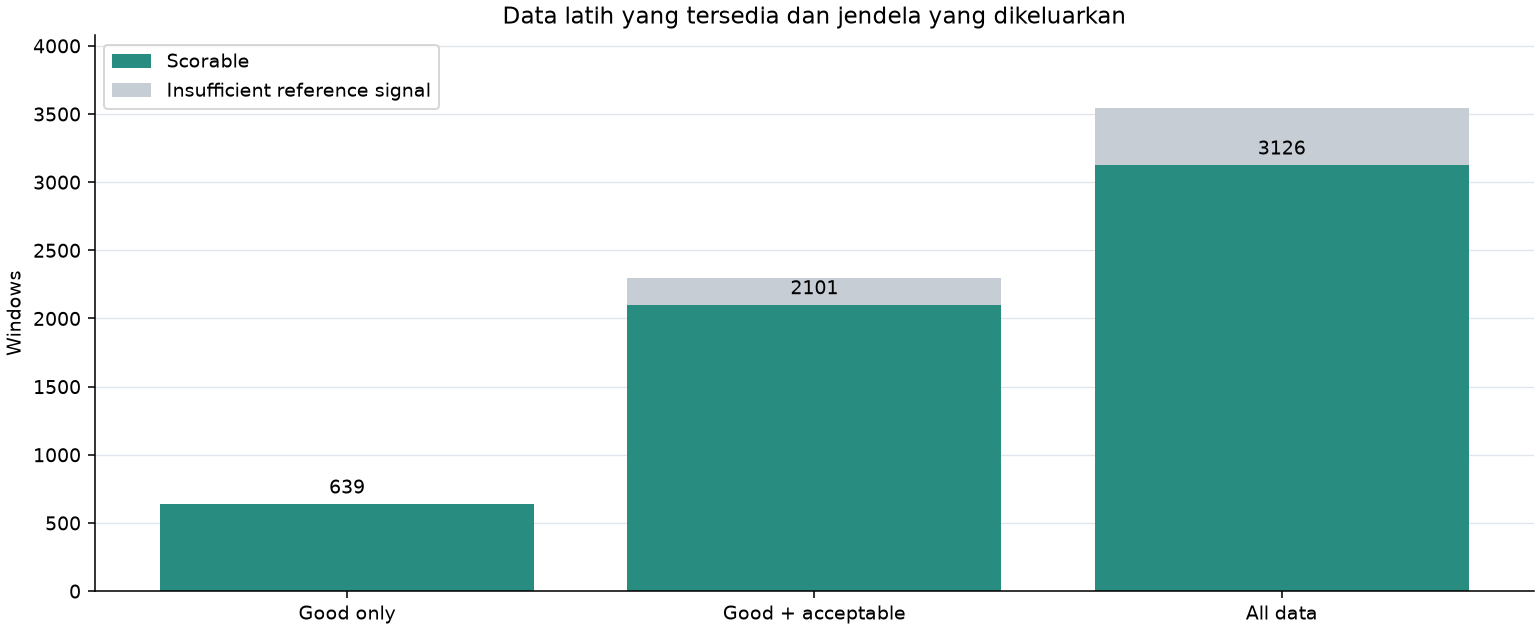

In [6]:
def show_chart(key):
    title, caption = visual.CHARTS[key]
    display(Markdown(f'### {title}\n\n{caption}'))
    display(Image(filename=str(reports[SELECTED_DATASET]['charts'][key])))

show_chart('data_coverage')


### 2. Bagaimana lima tingkat beban ditentukan?

Grafik ini memakai acuan seluruh data latih untuk model akhir. Skor kontinu menggabungkan komponen HRV dan mata, lalu dibagi menjadi lima tingkat menggunakan empat batas persentil acuan latih. Evaluasi peserta uji memakai acuan tersendiri yang tidak menyertakan peserta tersebut. Batas ini bersifat relatif, bukan ambang beban kognitif universal. Histogram menghitung jendela; penentuan batas memberi setiap peserta bobot yang sama.

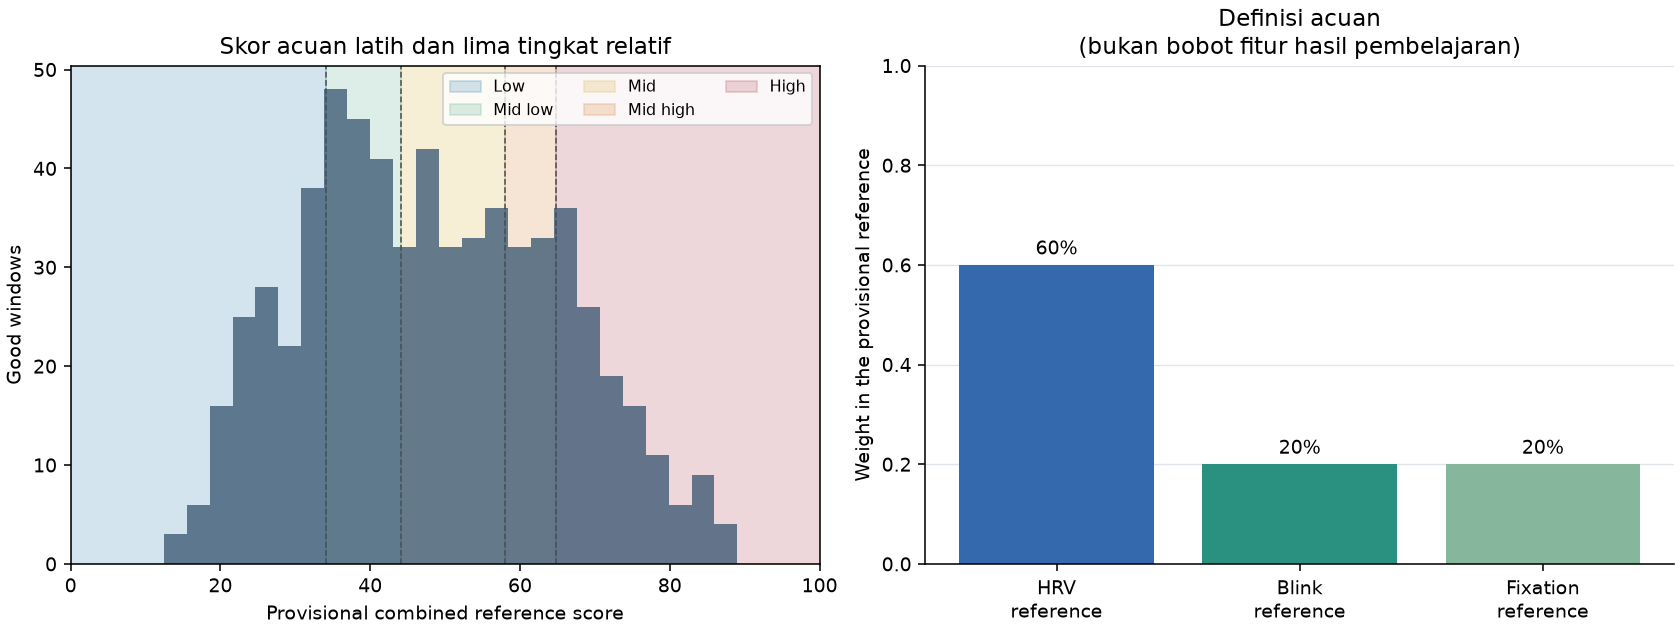

In [7]:
show_chart('reference_bands')


### 3. Pengukuran apa saja yang masuk ke model?

Semua prediktor HRV dan mata yang dikonfigurasi ditampilkan. Angka pada sel menunjukkan persentase nilai yang hilang. EAR, geometri iris, statistik tatapan, estimasi status mata, dan konteks kepala merupakan kandidat masukan. Proporsi status mata belum terklasifikasi atau lainnya hanya menjadi diagnostik. Estimasi iris bukan pengukuran diameter pupil.

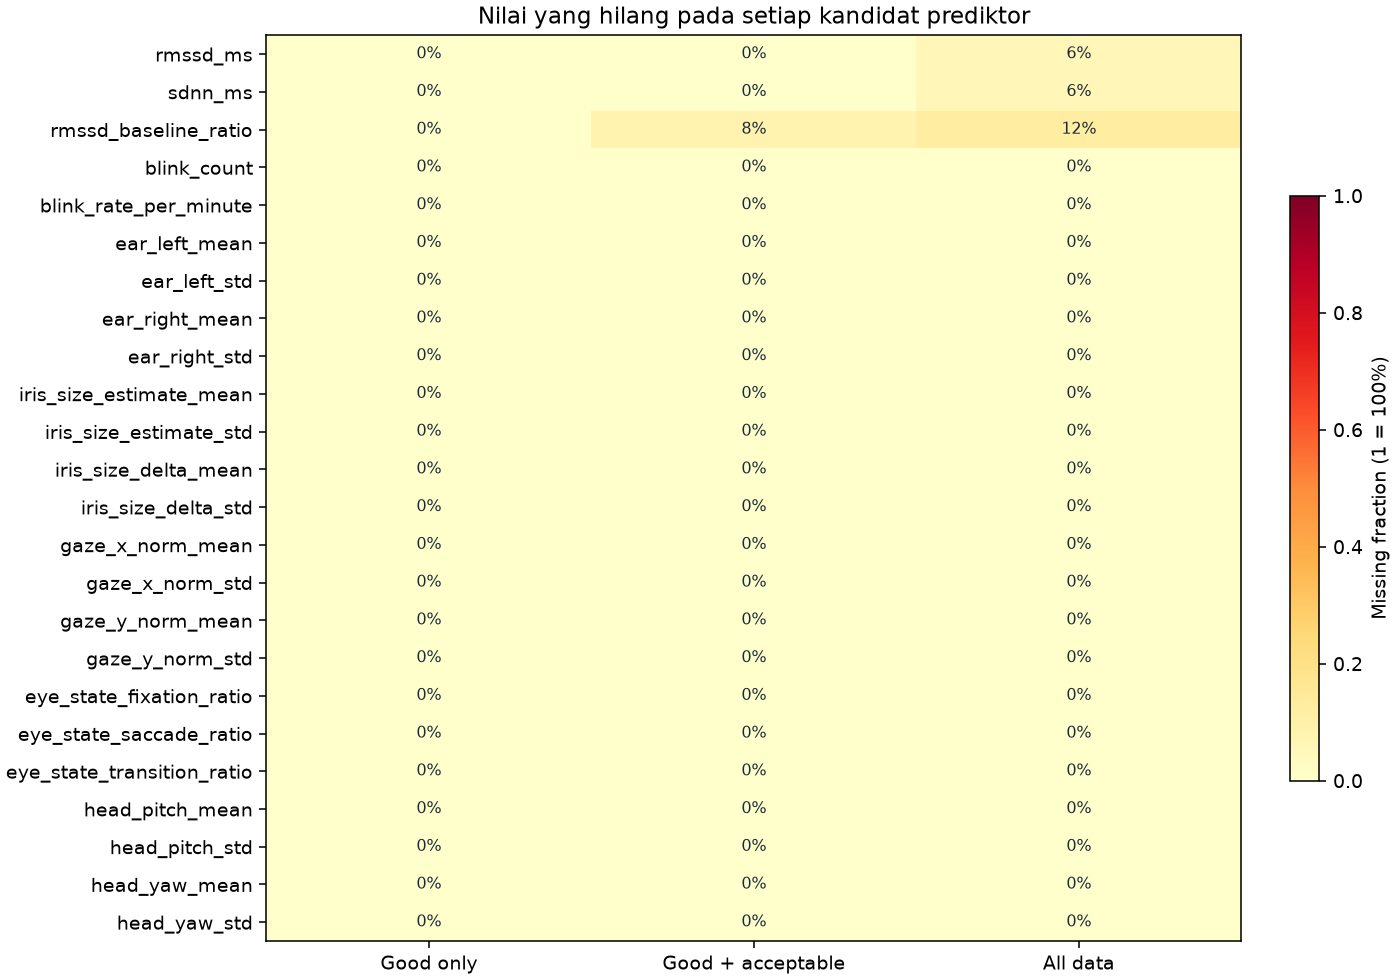

In [8]:
show_chart('missing_features')


### 4. Seberapa sesuai prediksi model dengan acuan sementara?

Macro-F1 rata-rata per peserta yang lebih tinggi berarti kesesuaian lebih baik; galat skor yang lebih rendah juga lebih baik. Setiap peserta uji memiliki bobot yang sama. Macro-F1 mencakup lima label; F1 kelas yang tidak muncul ditetapkan nol. Hasil ini mengukur peniruan aturan sensor yang dipilih, bukan akurasi terhadap pengukuran beban kognitif independen. Skor kedua cabang digabungkan sebelum tingkat beban ditentukan.

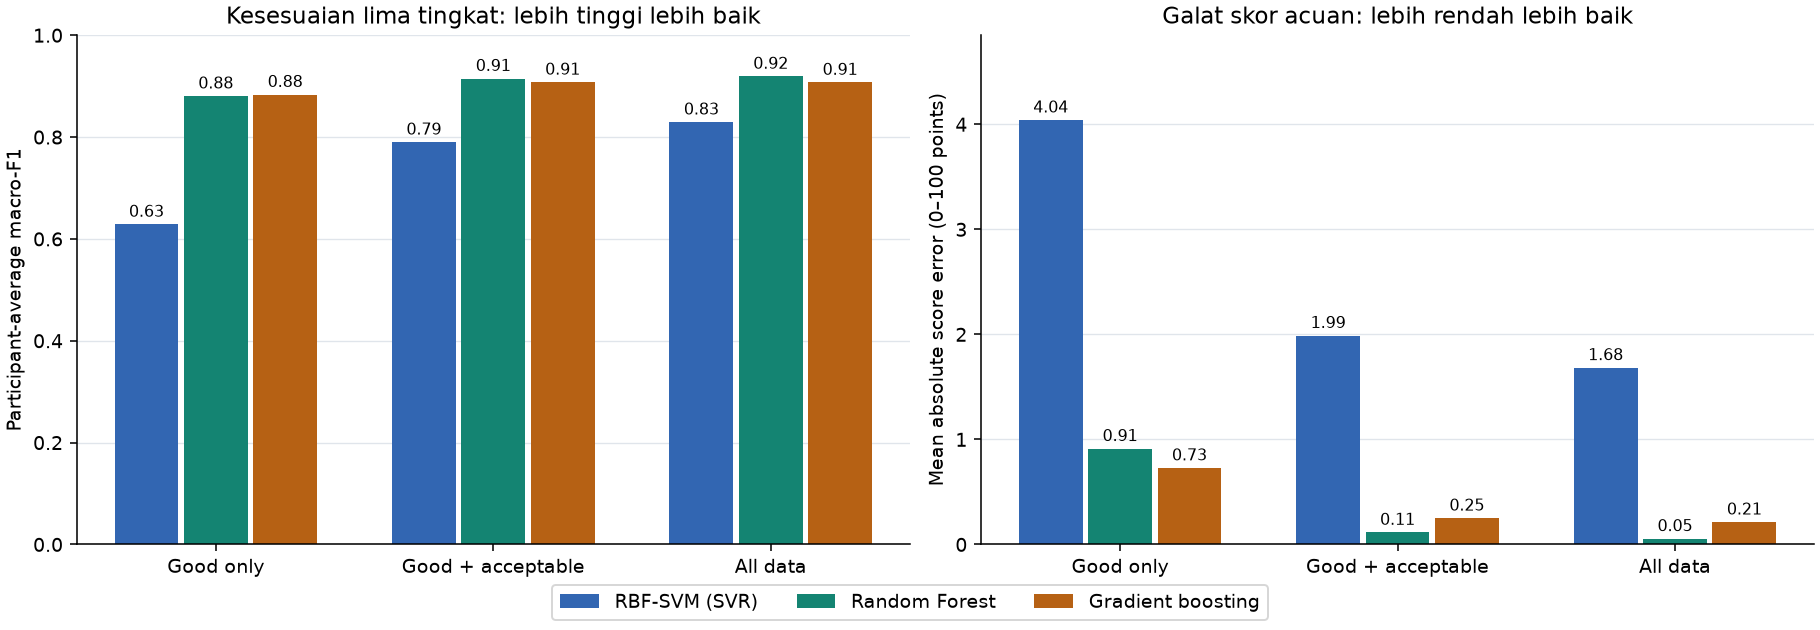

In [9]:
show_chart('model_agreement')


### 5. Tingkat mana yang sering tertukar?

Baris menunjukkan tingkat acuan sementara; kolom menunjukkan prediksi model. Setiap sel memuat persentase terhadap total baris acuan dan jumlah jendela. Diagonal yang kuat berarti prediksi sesuai dengan acuan. Sembilan panel memakai jendela uji yang sama, urutan label tetap, dan skala warna yang sama.

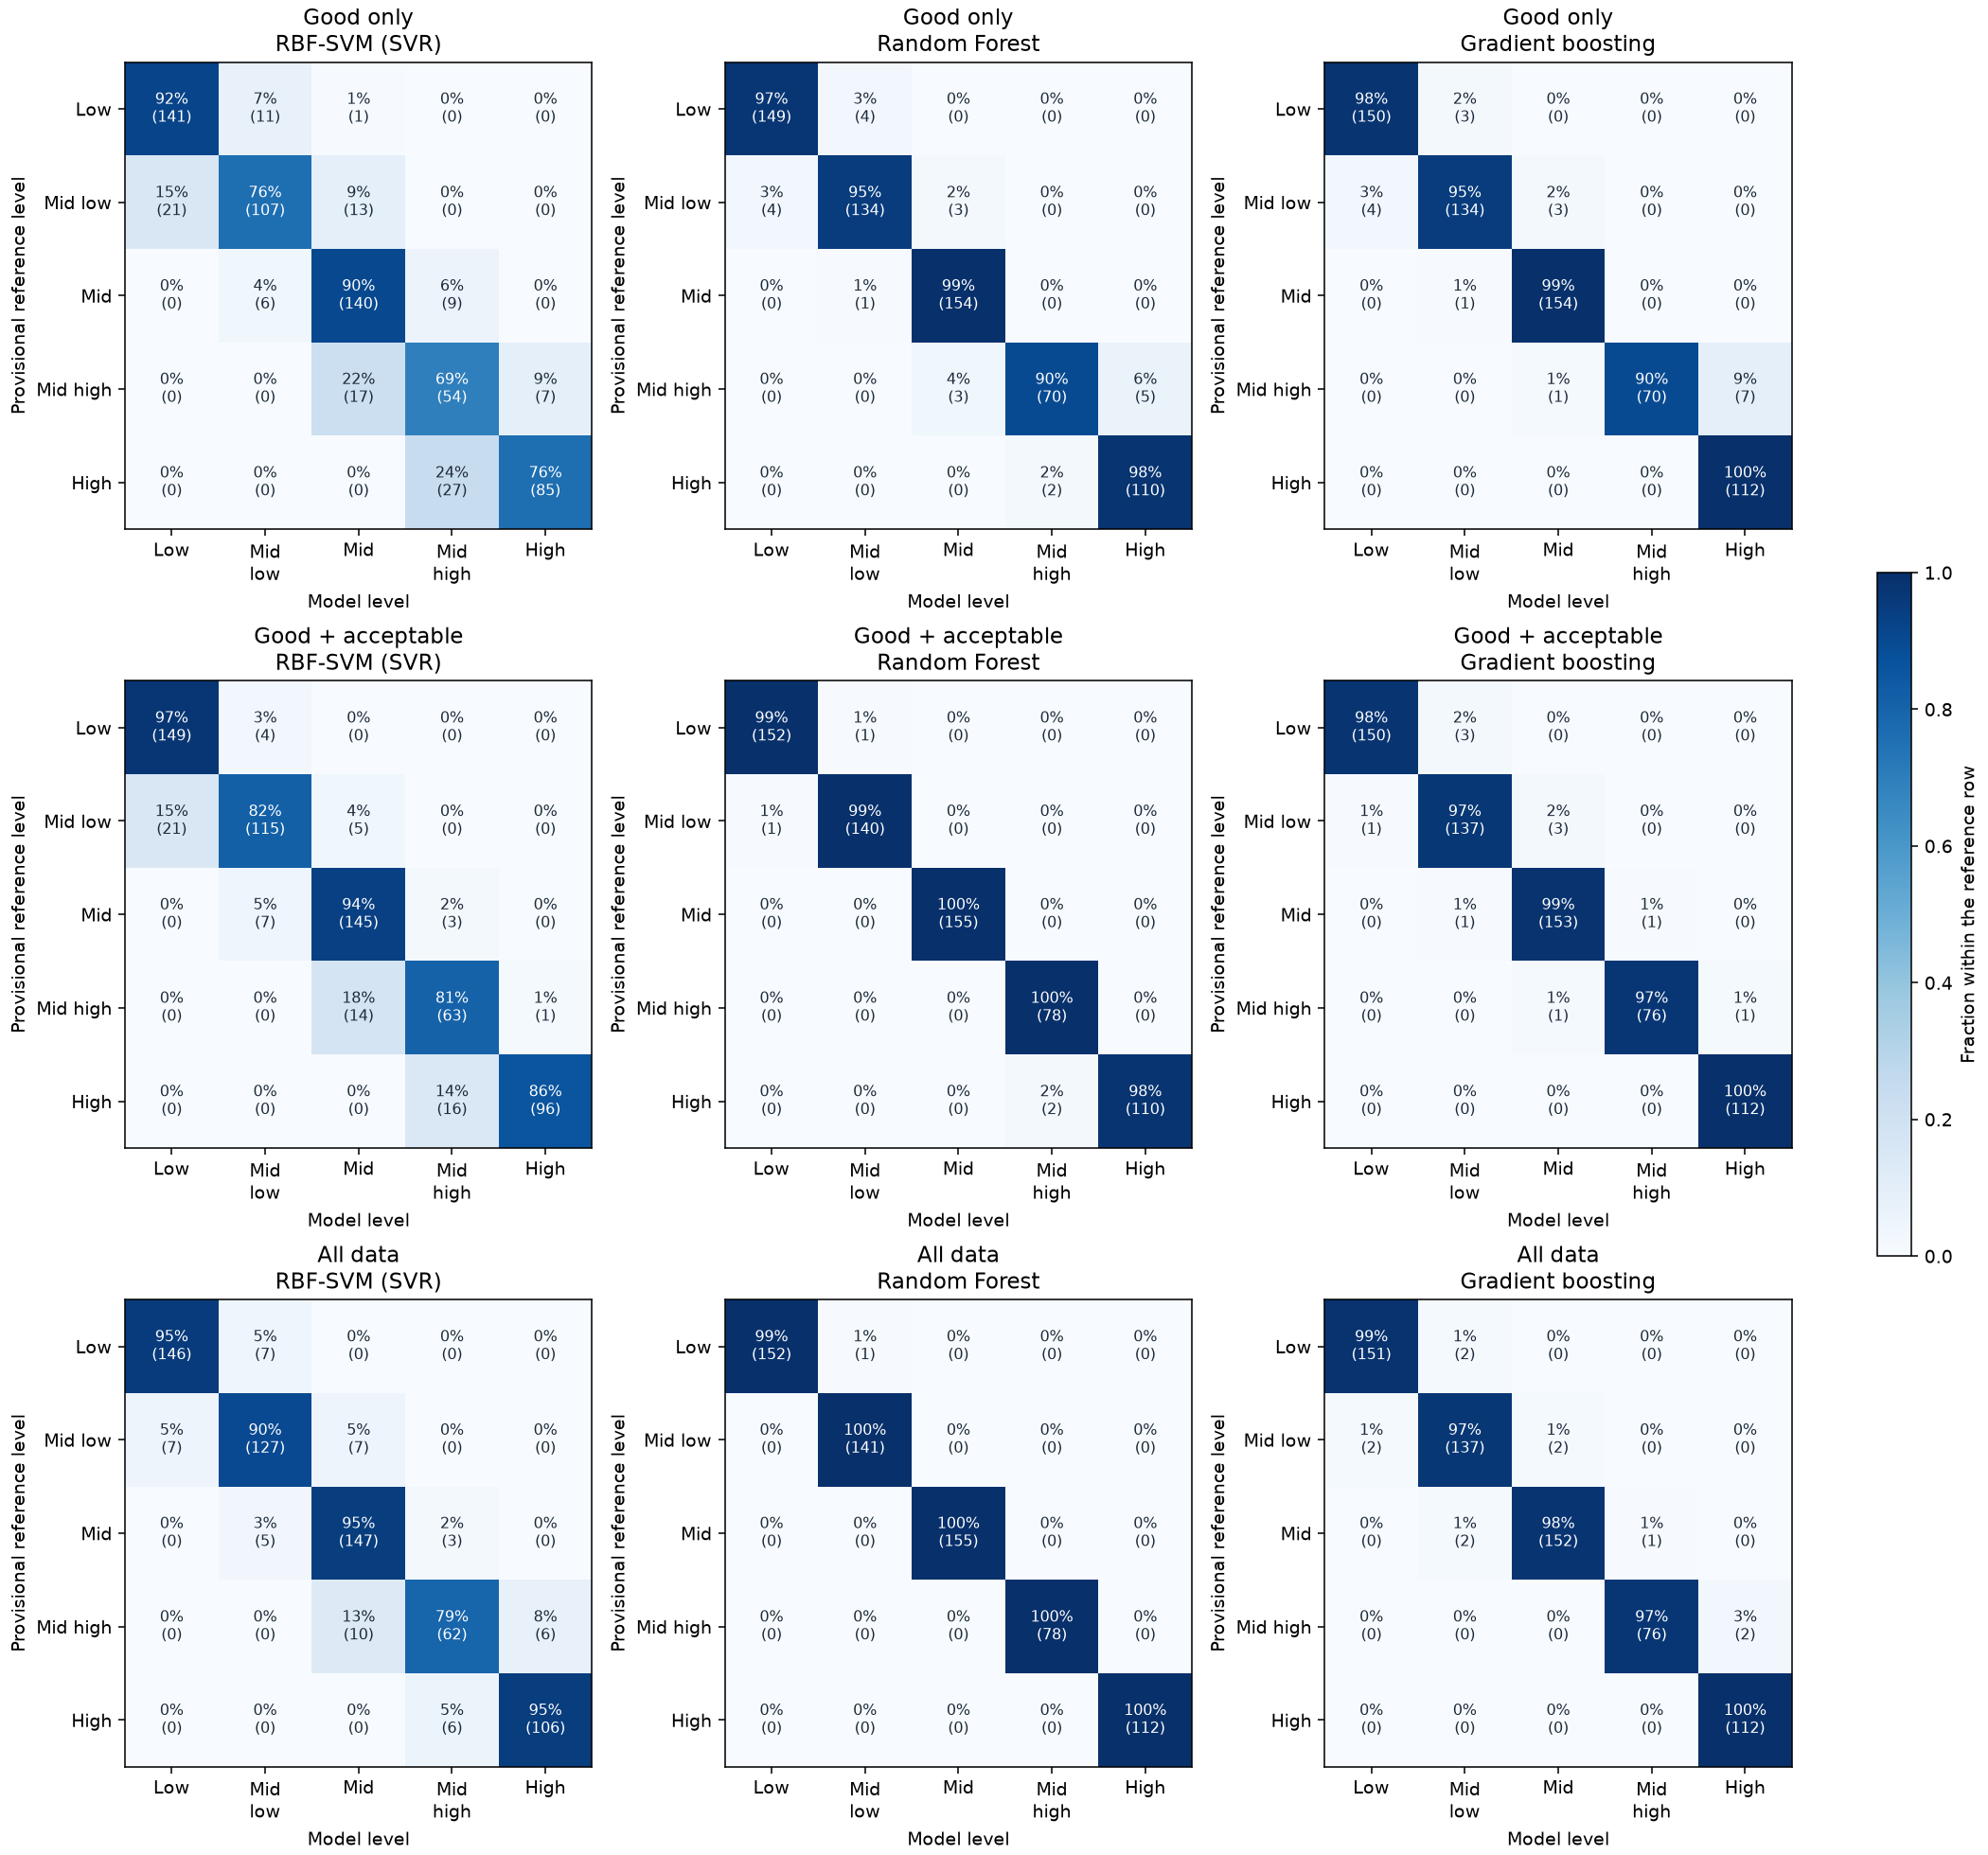

In [10]:
show_chart('confusion_matrices')


### 6. Apakah kesesuaiannya konsisten antarpeserta?

Setiap sel adalah macro-F1 lima label untuk satu peserta yang seluruh rekamannya dipisahkan dari pelatihan. Label kolom memuat jumlah jendela uji; sebagian peserta mungkin memiliki sedikit jendela atau tidak mencakup semua tingkat acuan. Variasi antarpeserta perlu diperhatikan karena jendela yang tumpang tindih bukan sampel independen. Nilai ini bukan interval kepercayaan atau pengukuran beban yang sudah divalidasi.

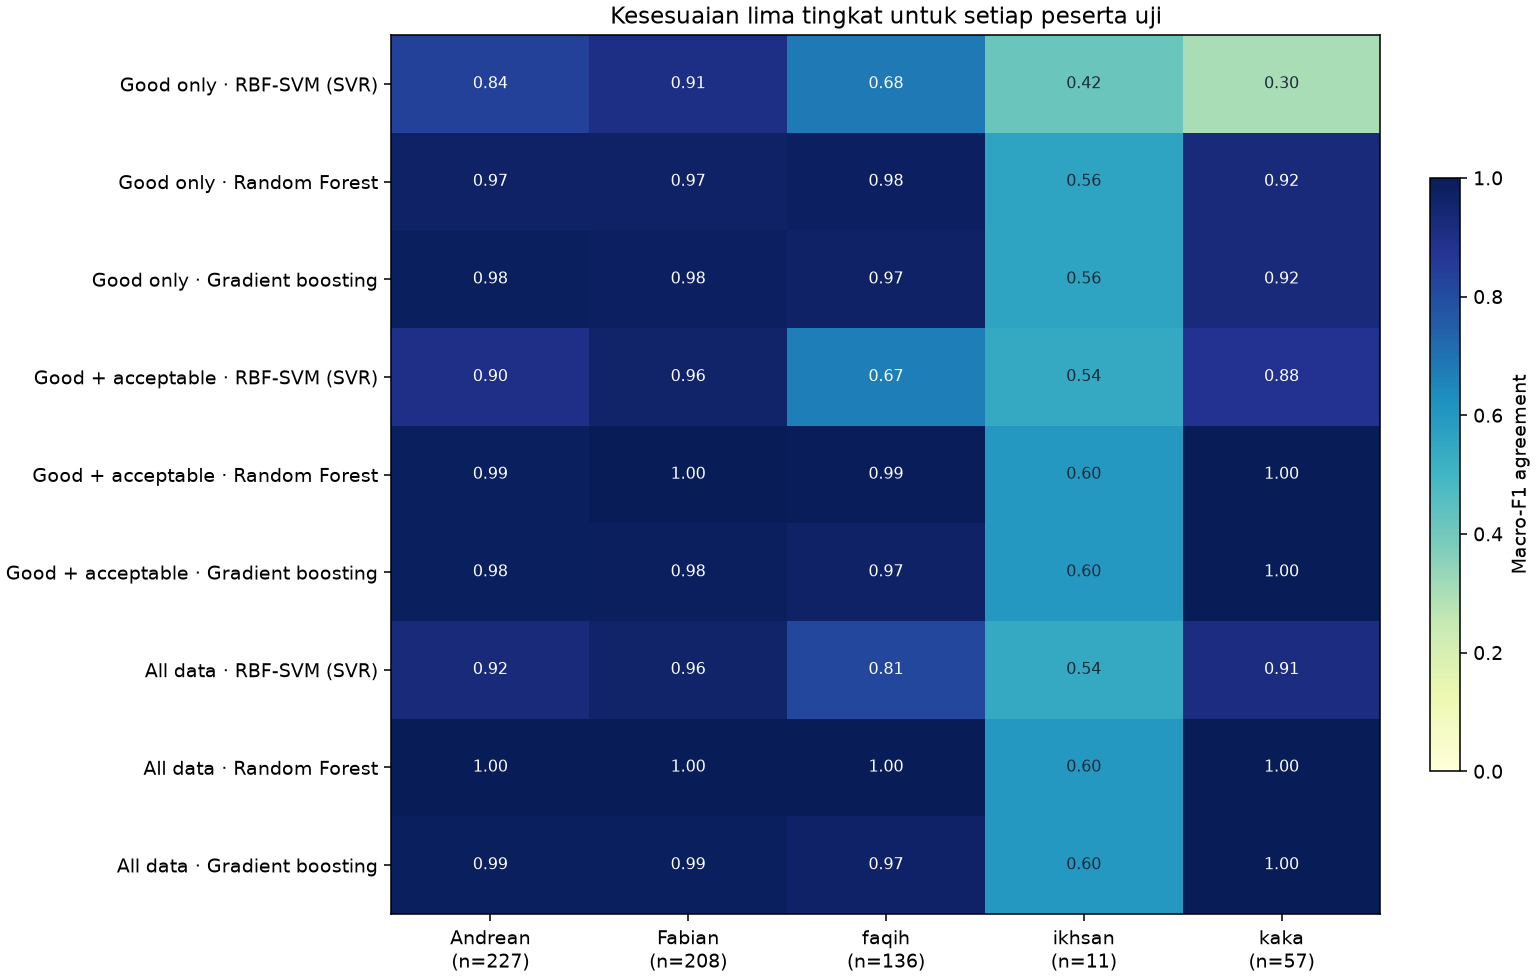

In [11]:
show_chart('participant_agreement')


### 7. Kelompok fitur mana yang memengaruhi prediksi?

Semua kolom dalam satu kelompok fitur digeser secara melingkar di dalam data peserta uji yang sama. Hubungan antarkolom dalam kelompok tetap terjaga, tetapi keselarasan dengan sinyal lain berubah. Nilai positif berarti galat skor meningkat; nilai negatif berarti perubahan tersebut kebetulan memperbaiki prediksi. Ini merupakan diagnostik ketergantungan model, bukan bukti sebab-akibat atau validitas fitur sebagai ukuran beban kognitif. Fitur berkorelasi dapat saling menggantikan; nilai kecil tidak berarti rekamannya sia-sia.

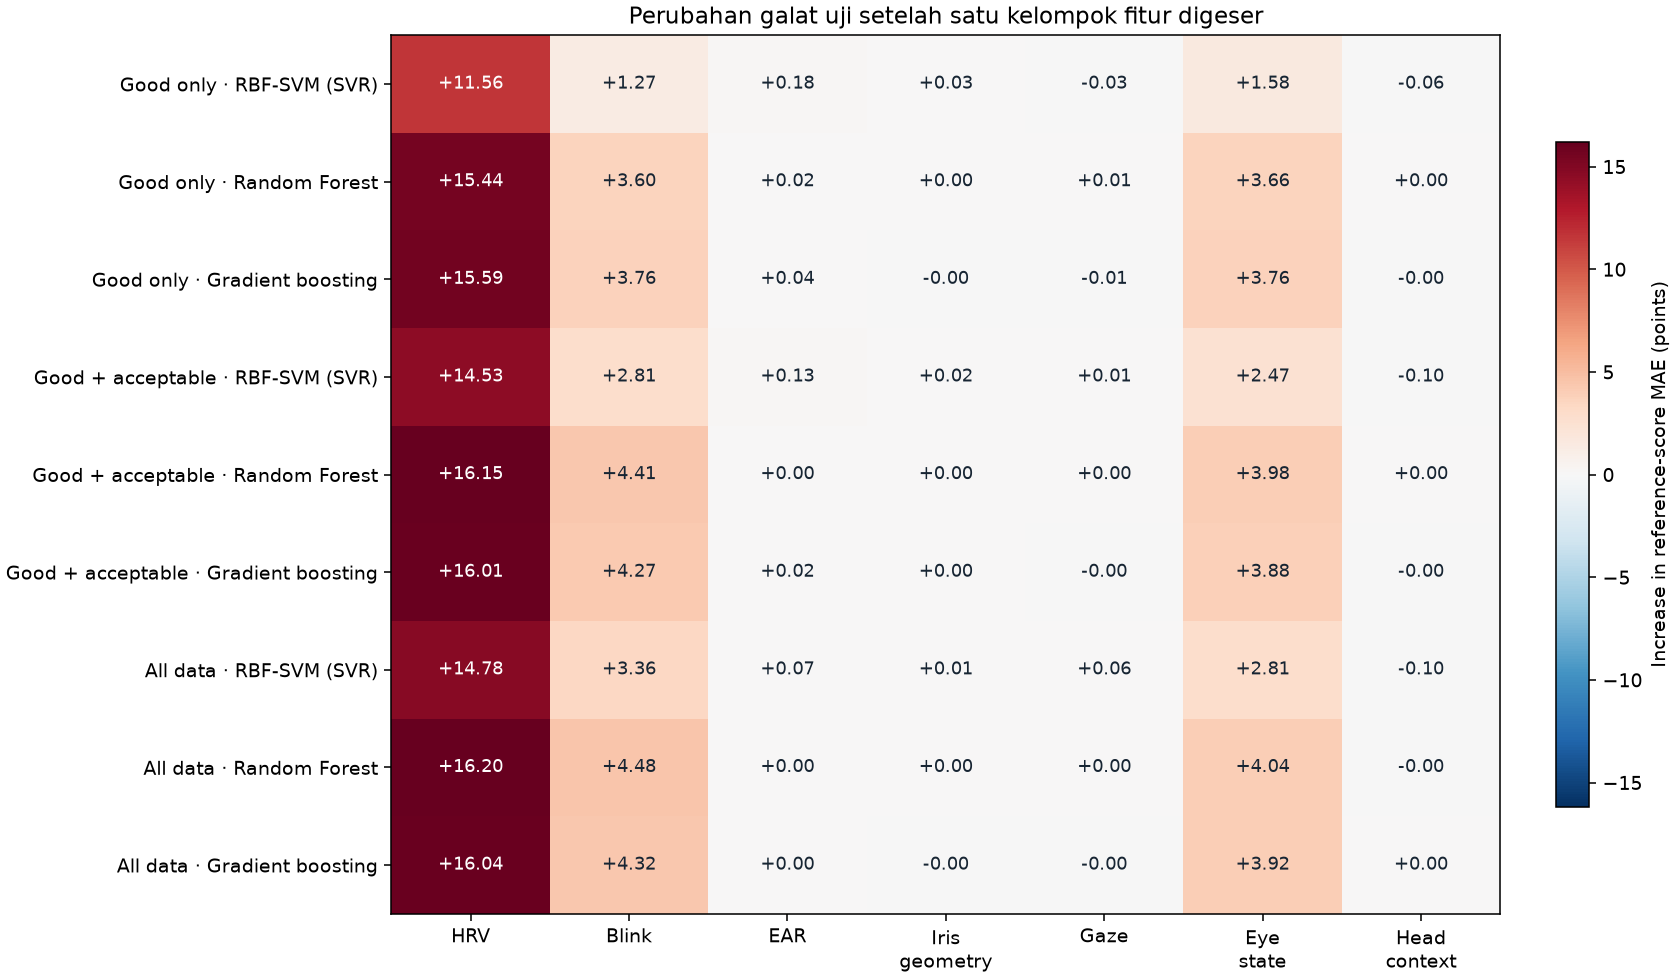

In [12]:
show_chart('feature_dependence')


### 8. Bagaimana kontribusi kedua cabang berubah sepanjang waktu?

Grafik memakai kandidat dengan kesesuaian tertinggi dan peserta dengan jendela uji terbanyak. Panel atas membandingkan estimasi skor gabungan dengan acuan sementara. Panel bawah menampilkan kontribusi HRV dan mata setelah dikalikan bobot; jumlahnya sama dengan estimasi skor gabungan. Setiap titik merangkum satu jendela. Garis penghubung tidak menambahkan pengukuran pada celah rekaman. Prediksi berasal dari evaluasi peserta uji, bukan model akhir yang diuji pada data latihnya sendiri.

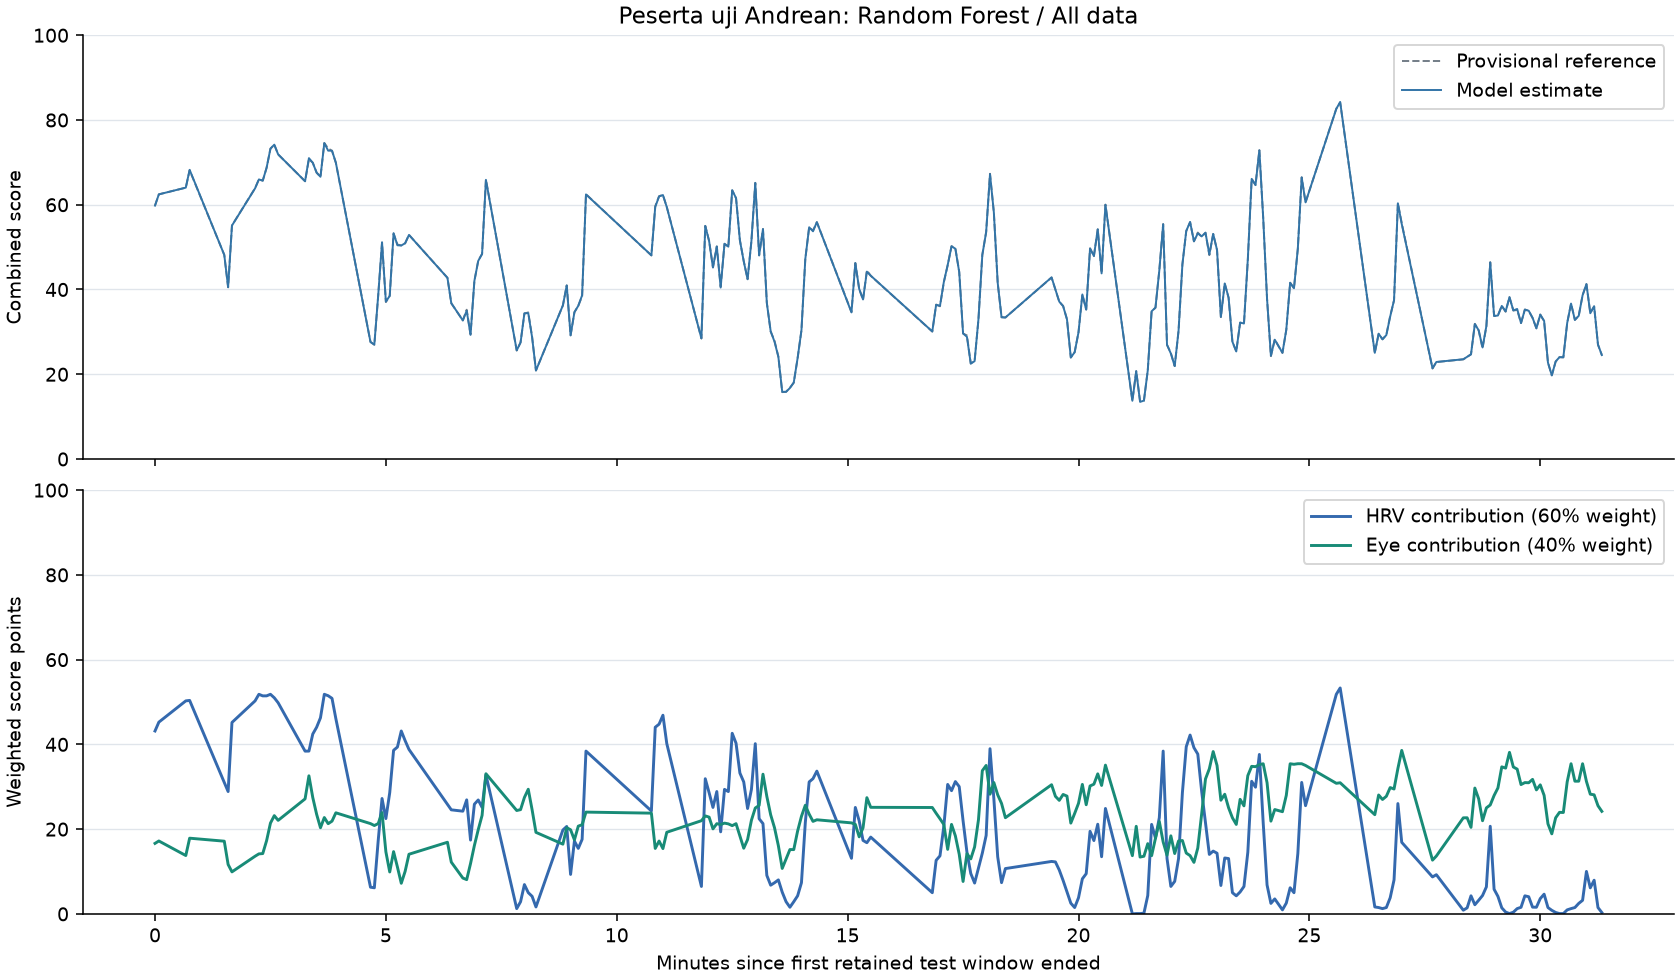

In [13]:
show_chart('branch_contributions')


### 9. Apa yang berubah pada pembobotan 50/50?

Grafik menunjukkan seberapa sering prediksi berganti tingkat ketika kedua cabang model yang sama digabungkan dengan bobot alternatif. Setiap rasio memiliki batas tingkat yang dihitung dari acuan latih yang sama. Pelatihan ulang tidak diperlukan karena target setiap cabang tidak bergantung pada bobot penggabungan. Banyaknya label yang berubah tidak membuktikan rasio mana yang lebih akurat mengukur beban kognitif sebenarnya.

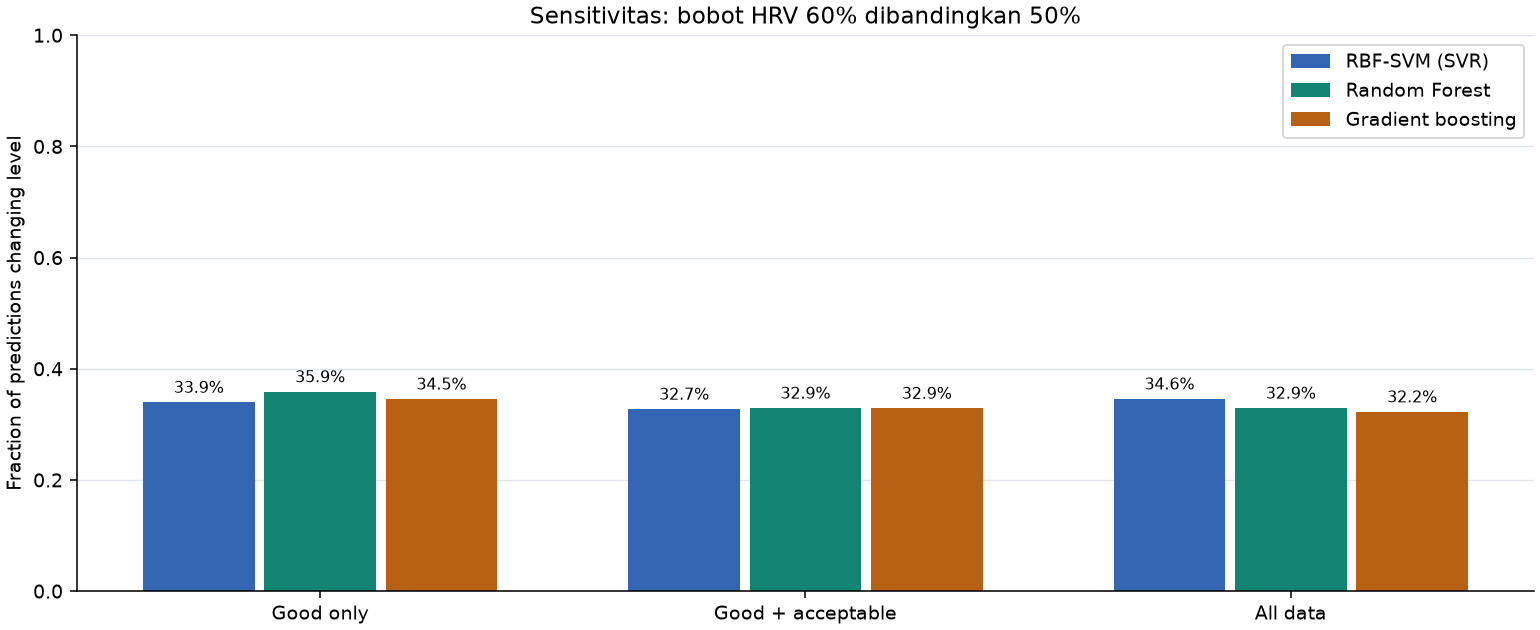

In [14]:
show_chart('weight_sensitivity')


## 8. Periksa keluaran uji dan kesalahan prediksi

Pilih varian dataset dan keluarga model di bawah. Prediksi berikut berasal dari model yang **tidak dilatih menggunakan data peserta yang ditampilkan**. Tabel memperlihatkan skor prediksi kedua cabang, skor gabungan, dan tingkat beban akhir.


In [15]:
INSPECT_VARIANT = 'good_acceptable'  # Pilihan: good_only, good_acceptable, all_data
INSPECT_MODEL = 'random_forest'    # Pilihan: svm, random_forest, gradient_boosting
held_out = pd.read_csv(result_directory / 'held_out_predictions.csv')
selected = held_out.loc[held_out.variant.eq(INSPECT_VARIANT) & held_out.model.eq(INSPECT_MODEL)]
columns = ['participant_id', 'reference_level', 'cognitive_load_level', 'hrv_score', 'eye_score', 'combined_score']
display(display_frame(selected[columns].head(10).round(3)))
errors = selected.loc[selected.reference_level != selected.cognitive_load_level]
print(f'{len(errors)} prediksi berbeda tingkat dari acuan pada {len(selected)} jendela uji.')
display(display_frame(errors[columns + ['reference_score']].head(10).round(3)))


4 prediksi berbeda tingkat dari acuan pada 639 jendela uji.


,participant_id,reference_level,cognitive_load_level,hrv_score,eye_score,combined_score
908,Andrean,Mid high,Mid high,71.934,41.531,59.772
909,Andrean,Mid high,Mid high,75.421,43.006,62.455
910,Andrean,Mid high,Mid high,83.712,34.474,64.017
911,Andrean,High,High,83.924,44.591,68.191
912,Andrean,Mid,Mid,51.677,43.040,48.222
913,Andrean,Mid low,Mid low,48.151,29.489,40.687
914,Andrean,Mid,Mid,75.297,24.903,55.140
915,Andrean,Mid high,Mid high,83.709,33.909,63.789
916,Andrean,High,High,86.364,35.411,65.983
917,Andrean,High,High,85.740,35.572,65.672


,participant_id,reference_level,cognitive_load_level,hrv_score,eye_score,combined_score,reference_score
983,Andrean,High,Mid high,66.783,61.479,64.661,65.159
1131,Andrean,Mid low,Low,10.251,69.813,34.076,34.519
2880,Fabian,Low,Mid low,12.342,67.924,34.575,34.514
4491,faqih,High,Mid high,55.196,78.299,64.438,65.985


## 9. Menggunakan model akhir yang disimpan

Contoh ini memperagakan antarmuka prediksi pada beberapa baris. Model akhir dilatih ulang menggunakan seluruh data latihnya sendiri, sehingga contoh ini **bukan skor evaluasi tambahan**. Gunakan keluaran peserta uji pada bagian sebelumnya untuk mengevaluasi model.

Hasil memuat tingkat beban, skor HRV dan mata, skor gabungan, bobot, serta status sinyal. Jika pengukuran acuan wajib hilang atau kualitas sinyal ditandai buruk, sistem tidak mengeluarkan tingkat prediksi. Masukan fitur tanpa metadata kualitas memperoleh status asli `quality_unverified`, yang ditampilkan sebagai kualitas belum terverifikasi. Aplikasi adaptif tetap perlu menerapkan kebijakan kualitasnya sendiri. Tidak ada probabilitas kelas atau estimasi keyakinan yang diklaim sudah tervalidasi.


In [16]:
candidate = summaries[0]
model_path = result_directory / 'models' / f'{candidate["variant"]}__{candidate["model"]}.joblib'
bundle = joblib.load(model_path)
example = loaded[SELECTED_DATASET]['views']['good_only'].head(5)
print('Model:', model_path.name)
print('Nama target pada antarmuka:', bundle['target'])
print('Makna target:', NOTE_ID)
display(display_frame(predict_windows(bundle, example).round(3)))


Model: all_data__random_forest.joblib
Nama target pada antarmuka: cognitive_load_level
Makna target: Estimasi relatif sementara berbasis HRV dan mata; belum divalidasi dengan pengukuran beban kognitif yang independen.


,window_id,participant_id,session_id,signal_status,cognitive_load_level,hrv_score,eye_score,combined_score,hrv_weight,eye_weight,label_source
0,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,ok,Mid high,75.580,38.741,60.845,0.6,0.4,provisional_relative_hrv_eye
1,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,ok,Mid high,78.752,40.659,63.515,0.6,0.4,provisional_relative_hrv_eye
2,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,ok,Mid high,86.010,31.358,64.150,0.6,0.4,provisional_relative_hrv_eye
3,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,ok,High,86.178,41.854,68.448,0.6,0.4,provisional_relative_hrv_eye
4,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,ok,Mid,56.655,40.216,50.079,0.6,0.4,provisional_relative_hrv_eye


## 10. Menemukan dan memahami setiap keluaran

| Berkas | Kegunaan |
|---|---|
| `visualizations/report.html`, `*.png` | Seluruh grafik dan penjelasan. HTML dapat dibagikan sebagai satu berkas mandiri. |
| `reference.json`, `reference_labels.csv` | Acuan seluruh data latih, batas tetap, skor dan label sementara, serta baris tanpa skor. |
| `held_out_predictions.csv` | Acuan tiap pembagian evaluasi, skor prediksi, kontribusi cabang, tingkat akhir, dan hasil bobot alternatif. |
| `comparison.csv`, `summary.json` | Metrik kesesuaian gabungan. JSON juga memuat matriks kekeliruan lima tingkat. |
| `participant_metrics.csv/json` | Kesesuaian per peserta, galat skor, galat urutan tingkat, recall setiap kelas, dan waktu komputasi. |
| `evaluation_folds.csv`, `data_coverage.csv` | Peserta uji, alasan pembagian evaluasi dilewati, serta jumlah data yang dikeluarkan. |
| `training_audit.json` | Peserta pembentuk acuan, pembagian validasi berdasarkan peserta, galat pemilihan parameter, dan pengaturan cabang terpilih. |
| `feature_inventory.csv`, `family_sensitivity.csv` | Prediktor setiap cabang serta diagnostik ketergantungan model pada kelompok fitur. |
| `models/*.joblib`, `models/*.json` | Sembilan paket model akhir, masing-masing dengan dua cabang, beserta metadata yang dapat dibaca. |
| `run_manifest.json` pada direktori induk | Status penyelesaian, konfigurasi, versi dependensi, dan hash pemeriksaan integritas. |

Kualitas data, jumlah sampel, dan komposisi peserta berubah bersamaan. Urutan tugas, kondisi kamera, kalibrasi, dan perbedaan individu dapat memengaruhi sinyal. Pengujian pada jendela berkualitas baik belum membuktikan keandalan terhadap masukan langsung berkualitas buruk. Perbandingan ilmiah antarukuran jendela memerlukan peserta dan cakupan tugas/waktu yang sepadan. Prediksi cepat tetap membutuhkan seluruh durasi pengamatan jendelanya.

Pengukuran beban independen diperlukan untuk memvalidasi akurasi terhadap beban kognitif sebenarnya. Untuk saat ini, perlakukan kelima tingkat sebagai acuan sensor sementara yang telah disepakati. Perilaku adaptasi aplikasi perlu diuji secara terpisah.
